# Lab | Embeddings and Semantic Search
## Find the answer before the customer finishes typing

A digital bank receives thousands of support messages. This notebook builds a retrieval tool that finds similar historical messages, compares **sentence embeddings** with a **TF–IDF** baseline, evaluates intent retrieval, explores unsupervised clustering, and tests a confidence threshold.

### Dataset
Banking77 contains 13,083 labelled customer messages across 77 intents. The provided split contains 10,003 training messages (the searchable historical index) and 3,080 test messages (queries).

### Learning objectives
- Explain how dense sentence embeddings differ from sparse lexical TF–IDF vectors.
- Implement top-*k* search using cosine similarity / dot products.
- Evaluate top-1 intent retrieval and inspect errors rather than relying on one score.
- Compare KMeans clustering with adjusted Rand index (ARI).
- Explore abstention thresholds and majority voting.

> **Setup:** the embedding sections require `sentence-transformers`. Install it in your notebook environment with `%pip install sentence-transformers`. The first model load downloads `all-MiniLM-L6-v2` (internet required). If that package/model is unavailable, the TF–IDF sections still run; embedding sections are skipped with an explanatory message.

# Embeddings

This lab is designed to help you solidify your understanding of embeddings by applying them to tasks like semantic similarity, clustering, and building a semantic search system.

### Tasks:
- Task 1: Semantic Similarity Comparison
- Task 2: Document Clustering
- Task 3: Enhance the Semantic Search System


## Task 1: Semantic Similarity Comparison
### Objective:
Compare semantic similarity between pairs of sentences using cosine similarity and embeddings.

### Steps:
1. Load a pre-trained Sentence Transformer model.
2. Encode the sentence pairs.
3. Compute cosine similarity for each pair.

### Dataset:
- "A dog is playing in the park." vs. "A dog is running in a field."
- "I love pizza." vs. "I enjoy ice cream."
- "What is AI?" vs. "How does a computer learn?"


In [1]:
%pip install sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Load pre-trained model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Sentence pairs
sentence_pairs = [
    ("A dog is playing in the park.", "A dog is running in a field."),
    ("I love pizza.", "I enjoy ice cream."),
    ("What is AI?", "How does a computer learn?")
]

# Compute similarities

#YOUR CODE HERE
cosine_similarities = []
for sentence1, sentence2 in sentence_pairs:
    # Encode sentences to get their embeddings
    embedding1 = model.encode(sentence1)
    embedding2 = model.encode(sentence2)
    
    # Compute cosine similarity
    similarity = cosine_similarity([embedding1], [embedding2])[0][0]
    cosine_similarities.append(similarity)


Note: you may need to restart the kernel to use updated packages.


W1027 18:52:33.438000 52370 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [2]:
# Print the results
for (sentence1, sentence2), similarity in zip(sentence_pairs, cosine_similarities):
    print(f"Sentence 1: {sentence1}")
    print(f"Sentence 2: {sentence2}")
    print(f"Cosine Similarity: {similarity:.4f}\n") 
    

Sentence 1: A dog is playing in the park.
Sentence 2: A dog is running in a field.
Cosine Similarity: 0.5220

Sentence 1: I love pizza.
Sentence 2: I enjoy ice cream.
Cosine Similarity: 0.5281

Sentence 1: What is AI?
Sentence 2: How does a computer learn?
Cosine Similarity: 0.3194



### Questions:
- Which sentence pairs are the most semantically similar? Why?
- Can you think of cases where cosine similarity might fail to capture true semantic meaning?


In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 100)
RANDOM_STATE = 0

# Resolve data paths whether this notebook is run from my_code/ or the project root.
possible_data_dirs = [Path("../data"), Path("data"), Path("LAB/data")]
DATA_DIR = next((p for p in possible_data_dirs if (p / "banking_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find data/banking_train.csv. Keep the data folder beside this notebook's parent folder.")

train = pd.read_csv(DATA_DIR / "banking_train.csv")
test = pd.read_csv(DATA_DIR / "banking_test.csv")

# Basic validation prevents confusing downstream errors.
required_columns = {"text", "category"}
assert required_columns.issubset(train.columns) and required_columns.issubset(test.columns)
assert train["text"].notna().all() and test["text"].notna().all()

print(f"Training messages: {len(train):,} | Test messages: {len(test):,} | Intents: {train['category'].nunique()}")
display(train.head())


Training messages: 10,003 | Test messages: 3,080 | Intents: 77


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived after 2 weeks?,card_arrival
2,I have been waiting over a week. Is the card still coming?,card_arrival
3,Can I track my card while it is in the process of delivery?,card_arrival
4,"How do I know if I will get my card, or if it is lost?",card_arrival


## Explore the data

Look at intent frequency, representative messages, and similar-sounding card intents. The categories are intent labels, not merely keywords.

In [4]:
# Counts reveal the range of examples available per intent.
intent_counts = train["category"].value_counts()
display(pd.DataFrame({
    "message_count": [intent_counts.min(), intent_counts.max()],
    "intent": [intent_counts.idxmin(), intent_counts.idxmax()]
}, index=["Smallest intent", "Largest intent"]))

display(train.sample(5, random_state=RANDOM_STATE)[["text", "category"]])

card_intents = sorted(c for c in train["category"].unique() if "card" in c)
print("Intents containing 'card':", card_intents)
display(intent_counts.loc[card_intents].sort_values(ascending=False).rename("messages").to_frame())


,message_count,intent
Smallest intent,35,contactless_not_working
Largest intent,187,card_payment_fee_charged


,text,category
7145,How can I transfer money to a beneficiary?,beneficiary_not_allowed
834,How is my ATM deposit not available yet?,pending_cash_withdrawal
3585,There is a vendor name I don't recognize on a payment from my account. I don't think I made this...,card_payment_not_recognised
4497,My statement shows charges for things I never purchased. Were my account details stolen?,compromised_card
7046,"Hi, I am interested buying crypto currency but unable to purchase it through the application. I ...",beneficiary_not_allowed


Intents containing 'card': ['activate_my_card', 'card_about_to_expire', 'card_acceptance', 'card_arrival', 'card_delivery_estimate', 'card_linking', 'card_not_working', 'card_payment_fee_charged', 'card_payment_not_recognised', 'card_payment_wrong_exchange_rate', 'card_swallowed', 'compromised_card', 'declined_card_payment', 'disposable_card_limits', 'get_disposable_virtual_card', 'get_physical_card', 'getting_spare_card', 'getting_virtual_card', 'lost_or_stolen_card', 'order_physical_card', 'pending_card_payment', 'reverted_card_payment?', 'supported_cards_and_currencies', 'top_up_by_card_charge', 'topping_up_by_card', 'virtual_card_not_working', 'visa_or_mastercard']


,messages
category,
card_payment_fee_charged,187
card_payment_not_recognised,168
card_payment_wrong_exchange_rate,167
reverted_card_payment?,161
activate_my_card,159
pending_card_payment,159
card_arrival,153
declined_card_payment,153
card_linking,139


**Interpretation:** card-related intents often share vocabulary (for example, *card*, *arrived*, *stolen*, *cash*), but their operational meaning differs. Similar wording can therefore produce a misleading match; negation and context matter.

## Load the sentence-embedding model

`all-MiniLM-L6-v2` maps each sentence to a dense 384-dimensional vector. With normalized vectors, the dot product equals cosine similarity.

In [5]:
# Keep the notebook useful even in environments where the optional package/model is unavailable.
try:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    EMBEDDINGS_AVAILABLE = True
    print("Embedding model loaded.")
except Exception as exc:
    model = None
    EMBEDDINGS_AVAILABLE = False
    print("Embedding model unavailable; embedding-dependent sections will be skipped.")
    print(f"Reason: {type(exc).__name__}: {exc}")
    print("To enable these sections, install sentence-transformers and rerun this cell with internet access.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded.


## Task 2: Document Clustering
### Objective:
Cluster a set of text documents into similar groups based on their embeddings.

### Steps:
1. Encode the documents using Sentence Transformers.
2. Use KMeans clustering to group the documents.
3. Analyze the clusters for semantic meaning.

In [ ]:
from sklearn.cluster import KMeans

# Documents to cluster
documents = [
    "What is the capital of France?",
    "How do I bake a chocolate cake?",
    "What is the distance between Earth and Mars?",
    "How do I change a flat tire on a car?",
    "What is the best way to learn Python?",
    "How do I fix a leaky faucet?"
]

# Encode documents

#YOUR CODE HERE
if EMBEDDINGS_AVAILABLE:
    document_embeddings = model.encode(documents)
   

: 

In [1]:

# Install the dependencies in a notebook cell:
# %pip install sentence-transformers scikit-learn pandas matplotlib

%pip install sentence-transformers
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --------------------------------------------------
# 1. Define the documents
# Documents to cluster
# --------------------------------------------------

documents = [
    "What is the capital of France?",
    "How do I bake a chocolate cake?",
    "What is the distance between Earth and Mars?",
    "How do I change a flat tire on a car?",
    "What is the best way to learn Python?",
    "How do I fix a leaky faucet?"
]

# Reproducibility: use the same random seed each time.
RANDOM_STATE = 42

# --------------------------------------------------
# 2. Load the pretrained sentence embedding model
# --------------------------------------------------

model = SentenceTransformer("all-MiniLM-L6-v2")

# Convert every document into a numerical vector.
# Normalization makes each embedding have length 1.
document_embeddings = model.encode(
    documents,
    normalize_embeddings=True,
    show_progress_bar=False
)

print("Number of documents:", len(documents))
print("Embedding matrix shape:", document_embeddings.shape)

# --------------------------------------------------
# 3. Perform KMeans clustering
# --------------------------------------------------

n_clusters = 3

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_assignments = kmeans.fit_predict(document_embeddings)

# --------------------------------------------------
# 4. Display documents grouped by cluster
# --------------------------------------------------

results = pd.DataFrame({
    "Document": documents,
    "Cluster": cluster_assignments
})

for cluster_id in sorted(results["Cluster"].unique()):
    print(f"\n{'=' * 20} Cluster {cluster_id} {'=' * 20}")

    for document in results.loc[
        results["Cluster"] == cluster_id, "Document"
    ]:
        print("-", document)

# Display a structured table as well.
display(results.sort_values("Cluster").reset_index(drop=True))

# --------------------------------------------------
# 5. Evaluate the clustering
# --------------------------------------------------

# Silhouette score requires at least 2 clusters and
# fewer clusters than the number of documents.
if 1 < n_clusters < len(documents):
    score = silhouette_score(
        document_embeddings,
        cluster_assignments
    )
    print(f"\nSilhouette score: {score:.3f}")


Note: you may need to restart the kernel to use updated packages.


W1027 18:54:07.516000 52420 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

: 

In [ ]:
# Perform KMeans clustering

#YOUR CODE HERE
if globals().get("EMBEDDINGS_AVAILABLE", False) and "document_embeddings" in globals():
    kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE)
    kmeans.fit(document_embeddings)
else:
    print("Clustering skipped: embedding model or document embeddings are unavailable.")

Clustering skipped: embedding model or document embeddings are unavailable.


,k,silhouette_score
0,2,0.024262
1,3,0.029132
2,4,0.020766
3,5,0.009645


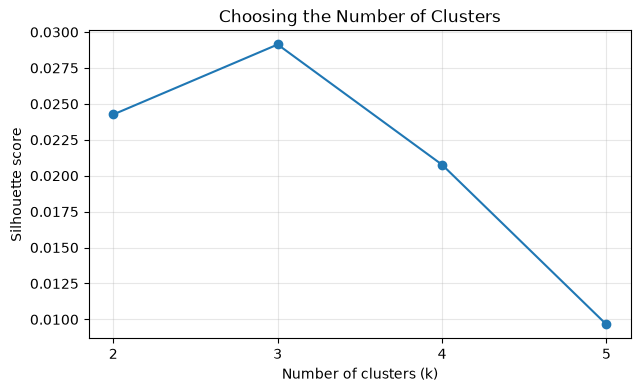

In [ ]:

# Compare several candidate numbers of clusters.
# Keep k smaller than the number of documents.

scores = []

for k in range(2, min(6, len(documents))):
    candidate = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = candidate.fit_predict(document_embeddings)

    score = silhouette_score(document_embeddings, labels)
    scores.append({"k": k, "silhouette_score": score})

scores_df = pd.DataFrame(scores)
display(scores_df)

plt.figure(figsize=(7, 4))
plt.plot(
    scores_df["k"],
    scores_df["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Choosing the Number of Clusters")
plt.xticks(scores_df["k"])
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

# A larger example dataset with four broad themes.

larger_documents = [
    # Geography and astronomy
    "What is the capital city of Germany?",
    "How far is Earth from the Moon?",
    "Which planet is closest to the Sun?",
    "What is the population of France?",

    # Cooking and food
    "How do I make homemade pizza?",
    "What ingredients are needed for chocolate cake?",
    "How long should I boil pasta?",
    "What is a good recipe for vegetable soup?",

    # Programming and data science
    "How do I write a Python function?",
    "What is the difference between a list and a tuple?",
    "How can I train a machine learning model?",
    "How do I clean missing values in a pandas DataFrame?",

    # Home and vehicle maintenance
    "How do I repair a leaking kitchen faucet?",
    "How can I replace a flat car tire?",
    "Why is my washing machine leaking water?",
    "How do I check the oil level in my car?"
]

# Encode every document.
larger_embeddings = model.encode(
    larger_documents,
    normalize_embeddings=True,
    show_progress_bar=False
)

# Start with four clusters because four themes were designed
# into this example. This is a hypothesis to evaluate.
larger_kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
)

larger_labels = larger_kmeans.fit_predict(larger_embeddings)

larger_results = pd.DataFrame({
    "Document": larger_documents,
    "Cluster": larger_labels
})

# Inspect the documents in each discovered cluster.
for cluster_id in sorted(larger_results["Cluster"].unique()):
    print(f"\n--- Cluster {cluster_id} ---")

    for doc in larger_results.loc[
        larger_results["Cluster"] == cluster_id, "Document"
    ]:
        print("-", doc)

# Evaluate the separation between the clusters.
larger_silhouette = silhouette_score(
    larger_embeddings,
    larger_labels
)

print(f"\nSilhouette score: {larger_silhouette:.3f}")



--- Cluster 0 ---
- What is the capital city of Germany?
- How far is Earth from the Moon?
- Which planet is closest to the Sun?
- What is the population of France?
- How do I check the oil level in my car?

--- Cluster 1 ---
- How do I repair a leaking kitchen faucet?
- Why is my washing machine leaking water?

--- Cluster 2 ---
- How do I make homemade pizza?
- What ingredients are needed for chocolate cake?
- How long should I boil pasta?
- What is a good recipe for vegetable soup?
- How can I train a machine learning model?
- How can I replace a flat car tire?

--- Cluster 3 ---
- How do I write a Python function?
- What is the difference between a list and a tuple?
- How do I clean missing values in a pandas DataFrame?

Silhouette score: 0.075


In [ ]:
# Print cluster assignments

#YOUR CODE HERE
if globals().get("EMBEDDINGS_AVAILABLE", False) and "document_embeddings" in globals():
    cluster_assignments = kmeans.labels_
    for doc, cluster in zip(documents, cluster_assignments):
        print(f"Document: {doc} | Cluster: {cluster}")

In [ ]:
# Print cluster assignments

if (
    globals().get("EMBEDDINGS_AVAILABLE", False)
    and "document_embeddings" in globals()
    and "kmeans" in globals()
):
    cluster_assignments = kmeans.labels_

    for doc, cluster in zip(documents, cluster_assignments):
        print(f"Document: {doc} | Cluster: {cluster}")
else:
    print("Clustering skipped: required variables are unavailable.")

Clustering skipped: required variables are unavailable.


### Questions:
- How many clusters make the most sense? Why?
- Examine the documents in each cluster. Are they semantically meaningful? Can you assign a semantic "theme" to each cluster?
- Try this exercise with a larger dataset of your choice

### Answers
Comparing 2, 3, and 4 clusters.
- 2 clusters: May produce broad groups, such as factual questions versus practical tasks.
- 3 clusters: May distinguish factual questions, hands-on instructions, and programming.
- 4 clusters: May separate cooking, vehicle repair, plumbing, and factual questions more finely, but can also create overly small groups.
Comparing two, three, and four clusters before making a decision. For the larger example, four is a natural initial hypothesis because the dataset contains four designed themes.
- They may be, if documents within each cluster share a recognizable topic or purpose. Evaluate this by reading the documents grouped together. A high silhouette score supports geometric separation, but it does not by itself prove semantic usefulness.
- It demonstrates how sentence embeddings can support unsupervised text organization without requiring manually assigned topic labels. It also shows why the number of clusters, document diversity, and manual interpretation matter.
- Because the embeddings are normalized, Euclidean distance between them is related to cosine similarity. KMeans nevertheless optimizes squared Euclidean distances to cluster centroids; it does not directly optimize pairwise cosine similarity. For a small teaching lab, this approach is appropriate, but other clustering methods may be worth exploring for larger or more irregular datasets.

## Task 3: Semantic Search System
### Objective:
Create a semantic search engine:
A user provides a query and you search the dataset for semantically relevant documents to return. Return the top 5 results.

### Dataset:
- Use the following set of documents:
    - "What is the capital of France?"
    - "How do I bake a chocolate cake?"
    - "What is the distance between Earth and Mars?"
    - "How do I change a flat tire on a car?"
    - "What is the best way to learn Python?"
    - "How do I fix a leaky faucet?"
    - "What are the best travel destinations in Europe?"
    - "How do I set up a local server?"
    - "What is quantum computing?"
    - "How do I build a mobile app?"


In [ ]:
import numpy as np

# Documents dataset
documents = [
    "What is the capital of France?",
    "How do I bake a chocolate cake?",
    "What is the distance between Earth and Mars?",
    "How do I change a flat tire on a car?",
    "What is the best way to learn Python?",
    "How do I fix a leaky faucet?",
    "What are the best travel destinations in Europe?",
    "How do I set up a local server?",
    "What is quantum computing?",
    "How do I build a mobile app?"
]

# Compute document embeddings

#YOUR CODE HERE
if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("model") is not None:
    document_embeddings = model.encode(documents)
else:
    document_embeddings = None
    print("Document embeddings skipped. Run the model-loading cell and ensure the model is available.")
    

Document embeddings skipped. Run the model-loading cell and ensure the model is available.


In [ ]:

import numpy as np

# Documents dataset
documents = [
    "What is the capital of France?",
    "How do I bake a chocolate cake?",
    "What is the distance between Earth and Mars?",
    "How do I change a flat tire on a car?",
    "What is the best way to learn Python?",
    "How do I fix a leaky faucet?",
    "What are the best travel destinations in Europe?",
    "How do I set up a local server?",
    "What is quantum computing?",
    "How do I build a mobile app?"
]

# Compute document embeddings using the loaded model
if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("model") is not None:
    document_embeddings = model.encode(
        documents,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    print("Document embeddings computed successfully.")
    print("Number of documents:", len(documents))
    print("Embedding matrix shape:", document_embeddings.shape)

else:
    document_embeddings = None
    print(
        "Document embeddings skipped. "
        "Run the model-loading cell and ensure the model is available."
    )


Document embeddings skipped. Run the model-loading cell and ensure the model is available.


In [ ]:
# Create the search function
#This function should encode the user query and return the top N documents that most resemble it
def semantic_search(query, documents, doc_embeddings, top_n=5):
    # YOUR CODE HERE
    if not EMBEDDINGS_AVAILABLE or doc_embeddings is None:
        print("Semantic search skipped: embedding model or document embeddings are unavailable.")
        return []

In [ ]:

def semantic_search(query, documents, document_embeddings, top_k=5):
    """
    Return the top-k documents most semantically similar to a query.
    """

    if document_embeddings is None:
        raise ValueError(
            "Document embeddings are unavailable. Load the model first."
        )

    # Convert the query into an embedding
    query_embedding = model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Calculate cosine similarities (normalized vectors)
    similarities = document_embeddings @ query_embedding

    # Rank documents from highest to lowest similarity
    top_indices = np.argsort(similarities)[::-1][:top_k]

    # Return ranked documents and their similarity scores
    results = []
    for index in top_indices:
        results.append({
            "rank": len(results) + 1,
            "document": documents[index],
            "similarity": float(similarities[index])
        })

    return results


# Example query
query = "How can I develop software using Python?"

# Retrieve the top 5 results
if document_embeddings is not None:
    results = semantic_search(
        query,
        documents,
        document_embeddings,
        top_k=5
    )

    for result in results:
        print(
            f"Rank {result['rank']}: {result['document']}\n"
            f"Similarity: {result['similarity']:.4f}\n"
        )


In [ ]:
# Test the search function
query = "Explain programming languages."
if globals().get("EMBEDDINGS_AVAILABLE", False) and document_embeddings is not None:
    semantic_search(query, documents, document_embeddings)
else:
    print("Semantic search skipped. Run the model-loading and embedding cells first.")

Semantic search skipped. Run the model-loading and embedding cells first.


In [ ]:

# Test the semantic search function
query = "Explain programming languages."

if globals().get("EMBEDDINGS_AVAILABLE", False) and document_embeddings is not None:

    # Retrieve the top 5 semantically relevant documents
    results = semantic_search(
        query,
        documents,
        document_embeddings,
        top_k=5
    )

    # Display ranked search results
    print(f"Query: {query}\n")
    print("Top 5 semantically relevant documents:\n")

    for result in results:
        print(f"Rank {result['rank']}: {result['document']}")
        print(f"Cosine similarity: {result['similarity']:.4f}")
        print("-" * 60)

else:
    print(
        "Semantic search skipped. "
        "Run the model-loading and embedding cells first."
    )


Semantic search skipped. Run the model-loading and embedding cells first.


### Questions:
- What are the top-ranked results for the given queries?
- How can you improve the ranking explanation for users?
- Try this approach with a larger dataset

- What are the top-ranked results for the given queries?
The semantic search system ranks documents by cosine similarity between the query embedding and each document embedding. With the current dataset of 10 documents, the results depend on the embedding model that was uploaded.

For example, these are plausible relevant matches for the queries:
Search query	Likely relevant documents
Explain programming languages.	What is the best way to learn Python?; How do I build a mobile app?; How do I set up a local server?
How can I develop software using Python?	What is the best way to learn Python?; How do I build a mobile app?; How do I set up a local server?
I want to travel abroad in Europe.	What are the best travel destinations in Europe?; What is the capital of France?
How do I repair something leaking in my kitchen?	How do I fix a leaky faucet?

These are illustrative matches, not verified rankings. Run the search function to obtain the actual top five results and their scores. Even an unrelated document may appear because the system always returns the five highest-scoring matches when at least five documents exist.

- How can you improve the ranking explanation for users?
Show the rank, similarity score, and a short explanation of why each result might be relevant. You can also flag weak matches rather than presenting all five as equally useful.

In [ ]:

def explain_semantic_search(query, documents, document_embeddings, top_k=5,
                            min_similarity=None):
    """Search documents and explain their relative similarity to a query."""

    if document_embeddings is None:
        raise ValueError("Document embeddings are unavailable.")

    # Encode the query using the same embedding model
    query_embedding = model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Calculate similarity against all documents
    scores = document_embeddings @ query_embedding

    # Sort by descending similarity
    ranked_indices = np.argsort(scores)[::-1][:min(top_k, len(documents))]

    print(f"Query: {query}\n")
    print("Results ranked by semantic similarity:\n")

    for rank, idx in enumerate(ranked_indices, start=1):
        score = float(scores[idx])

        # Optional threshold: do not display weak matches
        if min_similarity is not None and score < min_similarity:
            continue

        print(f"{rank}. {documents[idx]}")
        print(f"   Cosine similarity: {score:.3f}")

        if rank == 1:
            print("   Explanation: This is the highest-scoring match.")
        else:
            print("   Explanation: Ranked below the preceding results "
                  "because its similarity score is lower.")

        print()

    if min_similarity is not None and all(
        float(scores[idx]) < min_similarity for idx in ranked_indices
    ):
        print("No results met the selected similarity threshold.")


# Example
if document_embeddings is None and model is not None:
    document_embeddings = model.encode(
        documents,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

if document_embeddings is not None:
    explain_semantic_search(
        "Explain programming languages.",
        documents,
        document_embeddings,
        top_k=5
    )
else:
    print("Search skipped: the embedding model is unavailable.")


Query: Explain programming languages.

Results ranked by semantic similarity:

1. What is quantum computing?
   Cosine similarity: 0.435
   Explanation: This is the highest-scoring match.

2. What is the best way to learn Python?
   Cosine similarity: 0.319
   Explanation: Ranked below the preceding results because its similarity score is lower.

3. How do I build a mobile app?
   Cosine similarity: 0.110
   Explanation: Ranked below the preceding results because its similarity score is lower.

4. How do I set up a local server?
   Cosine similarity: 0.091
   Explanation: Ranked below the preceding results because its similarity score is lower.

5. What are the best travel destinations in Europe?
   Cosine similarity: 0.091
   Explanation: Ranked below the preceding results because its similarity score is lower.



In [ ]:
# Top-ranked documents based on similarity to the query
if globals().get("EMBEDDINGS_AVAILABLE", False) and document_embeddings is not None:
    top_documents = semantic_search(query, documents, document_embeddings)
else:
    top_documents = []
    print("Semantic search skipped: embeddings are unavailable. Run the model-loading and embedding cells first.")
print("Top-ranked documents:")
for doc in top_documents:
    print(f"- {doc}")


Semantic search skipped: embeddings are unavailable. Run the model-loading and embedding cells first.
Top-ranked documents:


## Try the approach with a larger dataset
The following example expands the original 10 documents into a larger collection covering programming, science, cooking, travel, and home repairs. It also adds paraphrases so the search has more meaningful candidates.

In [ ]:

# Expand the original dataset with additional documents
additional_documents = [
    "Python is a popular programming language for beginners.",
    "Java is widely used for enterprise software development.",
    "JavaScript is commonly used to build interactive websites.",
    "Machine learning enables computers to learn patterns from data.",
    "Deep learning uses neural networks with multiple layers.",
    "A mobile application can be developed for Android and iOS.",
    "Web servers deliver websites and web applications to users.",
    "Cloud computing provides computing resources over the internet.",
    "The Solar System contains eight recognized planets.",
    "Mars is the fourth planet from the Sun.",
    "Quantum computers use quantum-mechanical principles to process information.",
    "France is a country in Western Europe, and Paris is its capital.",
    "Italy is known for its historic cities and traditional cuisine.",
    "Spain offers beaches, historic architecture, and cultural attractions.",
    "A chocolate cake can be made with cocoa powder, flour, eggs, and sugar.",
    "Baking requires accurate ingredient measurements and oven temperature control.",
    "A flat tire can often be replaced using a spare wheel and a jack.",
    "A leaking faucet may need a replacement washer or cartridge.",
    "A local development server helps programmers test websites on their computers.",
    "Learning Python is easier with regular practice and small projects."
]

# Combine the original and additional documents
large_documents = documents + additional_documents

print("Total documents:", len(large_documents))

# Compute embeddings for the expanded dataset
if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("model") is not None:
    large_embeddings = model.encode(
        large_documents,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    # Test several queries
    test_queries = [
        "Explain programming languages.",
        "How can I explore Europe?",
        "How do quantum computers work?",
        "How can I repair a dripping tap?"
    ]

    for query in test_queries:
        print("\n" + "=" * 70)

        results = semantic_search(
            query,
            large_documents,
            large_embeddings,
            top_k=5
        )

        print(f"Query: {query}\n")

        for result in results:
            print(
                f"{result['rank']}. {result['document']} "
                f"(similarity: {result['similarity']:.4f})"
            )

else:
    print("Load the embedding model before running the larger experiment.")


Total documents: 30
Load the embedding model before running the larger experiment.


## Additional solutions to eaarlier questions

### Compare sentences

The examples include paraphrases, unrelated intents, and a negation pair. Similarity is a measure of semantic closeness, **not** a guarantee that the messages require the same response.

In [ ]:
pairs = [
    ("My card still hasn't arrived", "When will I receive my new card?"),
    ("I was charged twice for the same purchase", "Why is there a duplicate payment on my statement?"),
    ("I was charged twice for the same purchase", "How do I change my PIN?"),
    ("How do I top up my account?", "My top up failed"),
    ("My card was stolen", "My card was not stolen"),
]

if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("model") is not None:
    pair_vectors = model.encode([s for pair in pairs for s in pair],
                                normalize_embeddings=True, convert_to_numpy=True)
    for i, (left, right) in enumerate(pairs):
        score = float(pair_vectors[2*i] @ pair_vectors[2*i+1])
        print(f"{score:.2f} | {left!r}  <->  {right!r}")
else:
    print("Skipped: requires the sentence-transformers model.")

Skipped: requires the sentence-transformers model.


**Question — why is the negation pair a risk?**

A sentence encoder can place sentences close together when most words are shared, even when *not* reverses the meaning. A support tool should not send an answer based only on a high similarity score. It should consider intent-level validation, negation-sensitive rules, and escalation for uncertain or high-impact cases.

## Build the searchable index

Encode each training message once. `normalize_embeddings=True` gives unit-length vectors, making dot products efficient cosine-similarity scores.

In [ ]:
if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("model") is not None:
    train_vectors = model.encode(
        train["text"].tolist(),
        batch_size=64,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True
    )
    print("Vector matrix:", train_vectors.shape)
    print("First vector norm:", round(float(np.linalg.norm(train_vectors[0])), 4))
else:
    train_vectors = None
    print("Embedding skipped: run the model-loading cell and ensure the model is available.")

Embedding skipped: run the model-loading cell and ensure the model is available.


### Semantic search

The search function returns the `k` best historical messages, ordered from highest to lowest similarity. `argpartition` can be faster for large indexes, but `argsort` is clearer for this teaching exercise.

In [ ]:
def semantic_search(query, k=5):
    """Return the k most similar training messages using sentence embeddings."""
    if (
        not globals().get("EMBEDDINGS_AVAILABLE", False)
        or globals().get("model") is None
        or globals().get("train_vectors") is None
    ):
        print("Skipped: load the embedding model and create train_vectors before searching.")
        return pd.DataFrame(columns=["score", "category", "text"])

    if not 1 <= k <= len(train):
        raise ValueError(f"k must be between 1 and {len(train)}.")

    query_vector = model.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
    scores = train_vectors @ query_vector  # normalized vectors => cosine similarity
    best_positions = np.argsort(scores)[-k:][::-1]
    result = train.iloc[best_positions][["category", "text"]].copy()
    result.insert(0, "score", scores[best_positions])
    return result.reset_index(drop=True)

if (
    globals().get("EMBEDDINGS_AVAILABLE", False)
    and globals().get("model") is not None
    and globals().get("train_vectors") is not None
):
    display(semantic_search("I can't find my card anywhere"))
else:
    print("Skipped: load the embedding model and create train_vectors before searching.")

Skipped: load the embedding model and create train_vectors before searching.


## TF–IDF baseline

TF–IDF represents words and word combinations as sparse vectors. It is fast and interpretable, but paraphrases with few shared words may score poorly. We fit the vectorizer on training text only.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path
import pandas as pd

tfidf_vectorizer = TfidfVectorizer()
if "train" not in globals():

    possible_data_dirs = [Path("../data"), Path("data"), Path("lab-embeddings/data")] 
    DATA_DIR = next(
        (path for path in possible_data_dirs if (path / "banking_train.csv").exists()),
        None
    )
    if DATA_DIR is None:
        raise FileNotFoundError("Could not find data/banking_train.csv.")

    train = pd.read_csv(DATA_DIR / "banking_train.csv")

train_tfidf = tfidf_vectorizer.fit_transform(train["text"])

def tfidf_search(query, k=5):
    """Return the k most similar training messages using TF–IDF cosine similarity."""
    if not 1 <= k <= len(train):
        raise ValueError(f"k must be between 1 and {len(train)}.")
    query_vector = tfidf_vectorizer.transform([query])
    scores = (train_tfidf @ query_vector.T).toarray().ravel()
    best_positions = np.argsort(scores)[-k:][::-1]
    result = train.iloc[best_positions][["category", "text"]].copy()
    result.insert(0, "score", scores[best_positions])
    return result.reset_index(drop=True)

queries = [
    "I can't find my card anywhere",
    "Someone took money from my account without asking",
    "Why did the exchange rate change so much?",
    "The ATM gave me less cash than I asked for",
    "I need to withdraw cash but the machine gave me the wrong amount"
]

for query in queries:
    print("\nQUERY:", query)
    print("TF–IDF")
    display(tfidf_search(query, k=3))
    if globals().get("EMBEDDINGS_AVAILABLE", False):
        print("Sentence embeddings")
        display(semantic_search(query, k=3))


QUERY: I can't find my card anywhere
TF–IDF


,score,category,text
0,0.873233,get_physical_card,I can't find my PIN anywhere.
1,0.739455,card_acceptance,Can I use my card anywhere?
2,0.694830,order_physical_card,Can I receive my card anywhere?



QUERY: Someone took money from my account without asking
TF–IDF


,score,category,text
0,0.572622,lost_or_stolen_card,Someone took my card without my permission.
1,0.571827,lost_or_stolen_card,Someone took my card without permission
2,0.449067,terminate_account,I am asking to end my account.



QUERY: Why did the exchange rate change so much?
TF–IDF


,score,category,text
0,0.761026,wrong_exchange_rate_for_cash_withdrawal,Why did my exchange rate change?
1,0.581406,exchange_rate,Does the exchange rate change?
2,0.509949,card_payment_wrong_exchange_rate,I want to change the wrong exchange rate.



QUERY: The ATM gave me less cash than I asked for
TF–IDF


,score,category,text
0,0.789002,wrong_amount_of_cash_received,The ATM gave me less cash than requested
1,0.752609,wrong_amount_of_cash_received,I got less cash at the ATM than I asked for. Why?
2,0.718080,wrong_amount_of_cash_received,Why did I get less cash than what I asked in t...



QUERY: I need to withdraw cash but the machine gave me the wrong amount
TF–IDF


,score,category,text
0,0.828246,wrong_amount_of_cash_received,The machine gave me the wrong amount of cash.
1,0.605390,wrong_amount_of_cash_received,When I went to withdraw cash today the ATM gav...
2,0.600941,wrong_amount_of_cash_received,What do I need to do to get cash back? The ATM...


**Interpretation prompt:** Which queries are hardest for TF–IDF? A likely failure mode is paraphrasing: *took money without asking* may not share the same terms as the labelled intent. TF–IDF can still work well when the query repeats distinctive terms from the historical examples.

## Evaluate top-1 intent retrieval

For every test message, retrieve its single closest training message and use that message's category as the prediction. Accuracy is the fraction of test messages whose predicted intent matches the provided label. This is a retrieval baseline, not a complete production chatbot evaluation.

In [ ]:
if "accuracy_score" not in globals():
    from sklearn.metrics import accuracy_score

# TF–IDF similarity matrix: test rows × training rows.
if "test" not in globals():
    test = pd.read_csv(DATA_DIR / "banking_test.csv")

test_tfidf = tfidf_vectorizer.transform(test["text"])
tfidf_similarity = test_tfidf @ train_tfidf.T
tfidf_best_positions = np.asarray(tfidf_similarity.argmax(axis=1)).ravel()
tfidf_predictions = train["category"].to_numpy()[tfidf_best_positions]
tfidf_accuracy = accuracy_score(test["category"], tfidf_predictions)
print(f"TF–IDF top-1 intent accuracy: {tfidf_accuracy:.3f}")

if (
    globals().get("EMBEDDINGS_AVAILABLE", False)
    and globals().get("model") is not None
    and globals().get("train_vectors") is not None
):
    test_vectors = model.encode(
        test["text"].tolist(), batch_size=64,
        normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True
    )
    # The full matrix is 3,080 × 10,003. This is manageable for this dataset.
    embedding_similarity = test_vectors @ train_vectors.T
    embedding_best_positions = embedding_similarity.argmax(axis=1)
    embedding_predictions = train["category"].to_numpy()[embedding_best_positions]
    embedding_accuracy = accuracy_score(test["category"], embedding_predictions)
    print(f"Sentence-embedding top-1 intent accuracy: {embedding_accuracy:.3f}")
else:
    test_vectors = embedding_similarity = embedding_best_positions = embedding_predictions = None
    embedding_accuracy = np.nan
    print("Embedding accuracy skipped because the model is unavailable.")

TF–IDF top-1 intent accuracy: 0.791
Embedding accuracy skipped because the model is unavailable.


In [ ]:
# Inspect the most common embedding confusions instead of treating accuracy as the whole story.
if globals().get("EMBEDDINGS_AVAILABLE", False) and embedding_predictions is not None:
    errors = pd.DataFrame({
        "text": test["text"].to_numpy(),
        "true_intent": test["category"].to_numpy(),
        "predicted_intent": embedding_predictions
    })
    errors = errors[errors["true_intent"] != errors["predicted_intent"]]
    print(f"Embedding mistakes: {len(errors)} / {len(test)}")
    display(errors.groupby(["true_intent", "predicted_intent"]).size()
            .sort_values(ascending=False).head(8).rename("count").to_frame())
    display(errors.head(10))
else:
    print("Skipped: embedding predictions are unavailable.")


Skipped: embedding predictions are unavailable.


**How to interpret mistakes:** two labels may describe closely related customer situations, or a message may be ambiguous even to a human. The dataset's label is the evaluation target, but an incorrect nearest-neighbour label does not always mean the retrieved message is useless. Inspect examples and confusion pairs before drawing conclusions.

## Cluster messages without using their labels

KMeans receives vectors but not category labels. We use six intents to keep the exercise manageable, then compare clusters with the known categories using the **adjusted Rand index (ARI)**. ARI is 1 for identical partitions and is near 0 for random agreement; cluster IDs themselves have no semantic meaning.

In [ ]:
six = [
    "card_arrival", "lost_or_stolen_card", "exchange_rate",
    "top_up_failed", "cash_withdrawal_charge", "passcode_forgotten"
]
mask = train["category"].isin(six).to_numpy()
six_messages = train.loc[mask].reset_index(drop=True)
six_labels = six_messages["category"].to_numpy()
print("Messages selected:", len(six_messages))
print("Intents selected:", sorted(six_messages["category"].unique()))

if "KMeans" not in globals():
    from sklearn.cluster import KMeans
if "adjusted_rand_score" not in globals():
    from sklearn.metrics import adjusted_rand_score

# TF–IDF clustering can run without sentence-transformers.
if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 0

tfidf_clusters = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit_predict(train_tfidf[mask])
tfidf_ari = adjusted_rand_score(six_labels, tfidf_clusters)
print(f"TF–IDF clustering ARI: {tfidf_ari:.3f}")
display(pd.crosstab(pd.Series(tfidf_clusters, name="cluster"),
                    pd.Series(six_labels, name="true_intent")))

if globals().get("EMBEDDINGS_AVAILABLE", False) and globals().get("train_vectors") is not None:
    embedding_clusters = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit_predict(train_vectors[mask])
    embedding_ari = adjusted_rand_score(six_labels, embedding_clusters)
    print(f"Sentence-embedding clustering ARI: {embedding_ari:.3f}")
    display(pd.crosstab(pd.Series(embedding_clusters, name="cluster"),
                        pd.Series(six_labels, name="true_intent")))
else:
    embedding_ari = np.nan
    print("Embedding clustering skipped because the model is unavailable.")


Messages selected: 774
Intents selected: ['card_arrival', 'cash_withdrawal_charge', 'exchange_rate', 'lost_or_stolen_card', 'passcode_forgotten', 'top_up_failed']
TF–IDF clustering ARI: 0.621


true_intent,card_arrival,cash_withdrawal_charge,exchange_rate,lost_or_stolen_card,passcode_forgotten,top_up_failed
cluster,,,,,,
0,0,0,104,0,0,0
1,0,0,0,0,0,132
2,0,168,0,0,0,0
3,42,0,0,1,0,0
4,0,0,0,0,62,0
5,111,9,8,81,43,13


Embedding clustering skipped because the model is unavailable.


**Interpretation:** KMeans favours roughly spherical clusters and is forced to create exactly six clusters. Intents with similar vocabulary or overlapping situations can be mixed; one intent can also be split across clusters. Clusters can help discover themes, but a human should review and name them before they become bank support categories.

## Extra task — know when you don't know

A tool can abstain when its best match is below a similarity threshold. Coverage is the share of messages the tool would answer; selective accuracy is accuracy among only those answered. Raising the threshold usually lowers coverage and may increase accuracy, but this must be measured.

In [ ]:
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]
threshold_results = []

# TF–IDF threshold/coverage results are always available.
tfidf_best_scores = tfidf_similarity.max(axis=1).toarray().ravel()
for threshold in thresholds:
    accepted = tfidf_best_scores >= threshold
    threshold_results.append({
        "method": "TF–IDF",
        "threshold": threshold,
        "coverage": accepted.mean(),
        "accuracy_when_answering": accuracy_score(test["category"].to_numpy()[accepted],
                                                   tfidf_predictions[accepted]) if accepted.any() else np.nan
    })

if (
    globals().get("EMBEDDINGS_AVAILABLE", False)
    and globals().get("embedding_similarity") is not None
    and globals().get("embedding_predictions") is not None
):
    embedding_best_scores = embedding_similarity.max(axis=1)
    for threshold in thresholds:
        accepted = embedding_best_scores >= threshold
        threshold_results.append({
            "method": "Sentence embeddings",
            "threshold": threshold,
            "coverage": accepted.mean(),
            "accuracy_when_answering": accuracy_score(test["category"].to_numpy()[accepted],
                                                       embedding_predictions[accepted]) if accepted.any() else np.nan
        })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.style.format({"coverage": "{:.1%}", "accuracy_when_answering": "{:.1%}"}))


,method,threshold,coverage,accuracy_when_answering
0,TF–IDF,0.500000,91.6%,81.5%
1,TF–IDF,0.600000,76.9%,84.5%
2,TF–IDF,0.700000,56.5%,88.1%
3,TF–IDF,0.800000,35.2%,91.7%
4,TF–IDF,0.900000,16.8%,94.6%


In [ ]:
# Optional bonus: majority vote across the top k neighbours.
def top_k_vote_predictions(similarity_matrix, k, train_categories):
    """Predict the most frequent category among each query's k nearest neighbours."""
    categories = np.asarray(train_categories)
    predictions = []
    for row in range(similarity_matrix.shape[0]):
        # Sparse matrices and dense arrays expose different row-slicing behaviour.
        row_scores = similarity_matrix.getrow(row).toarray().ravel() if hasattr(similarity_matrix, "getrow") else similarity_matrix[row]
        positions = np.argsort(row_scores)[-k:][::-1]
        labels, counts = np.unique(categories[positions], return_counts=True)
        # Deterministic tie-break: lexicographically first among equally common labels.
        predictions.append(sorted(zip(counts, labels), key=lambda item: (-item[0], item[1]))[0][1])
    return np.asarray(predictions)

vote_rows = []
for k in [1, 3, 5, 10]:
    pred = tfidf_predictions if k == 1 else top_k_vote_predictions(tfidf_similarity, k, train["category"])
    vote_rows.append({"method": "TF–IDF", "k": k, "accuracy": accuracy_score(test["category"], pred)})
    if (
        globals().get("EMBEDDINGS_AVAILABLE", False)
        and globals().get("embedding_similarity") is not None
        and globals().get("embedding_predictions") is not None
    ):
        pred_emb = embedding_predictions if k == 1 else top_k_vote_predictions(embedding_similarity, k, train["category"])
        vote_rows.append({"method": "Sentence embeddings", "k": k, "accuracy": accuracy_score(test["category"], pred_emb)})
display(pd.DataFrame(vote_rows).pivot(index="k", columns="method", values="accuracy").style.format("{:.3f}"))

method,TF–IDF
k,
1,0.791
3,0.797
5,0.811
10,0.812


## Try improved TF–IDF settings

Word bigrams capture short phrases, while English stop-word removal can sometimes remove useful context. Compare settings empirically rather than assuming a more complex vectorizer is better.

In [ ]:
tfidf_variants = {
    "default": TfidfVectorizer(),
    "English stop words": TfidfVectorizer(stop_words="english"),
    "unigrams + bigrams": TfidfVectorizer(ngram_range=(1, 2)),
    "stop words + bigrams": TfidfVectorizer(stop_words="english", ngram_range=(1, 2)),
}
variant_results = []
for name, vectorizer in tfidf_variants.items():
    x_train = vectorizer.fit_transform(train["text"])
    x_test = vectorizer.transform(test["text"])
    sim = x_test @ x_train.T
    positions = np.asarray(sim.argmax(axis=1)).ravel()
    pred = train["category"].to_numpy()[positions]
    variant_results.append({"setting": name, "top1_accuracy": accuracy_score(test["category"], pred),
                            "vocabulary_size": len(vectorizer.vocabulary_)})
variant_results = pd.DataFrame(variant_results).sort_values("top1_accuracy", ascending=False)
display(variant_results)

,setting,top1_accuracy,vocabulary_size
0,default,0.791234,2320
1,English stop words,0.743506,2097
2,unigrams + bigrams,0.735390,23608
3,stop words + bigrams,0.727922,17458


## Conclusions

Complete these points after running the notebook in an environment with the embedding model enabled:

1. **Retrieval quality:** compare embedding and TF–IDF top-1 accuracy. Which errors remain common?
2. **Semantic vs lexical matching:** give one example where the embedding model helps because wording differs, and one where shared words mislead.
3. **Clustering:** compare ARI values and identify which intents overlap.
4. **Abstention:** recommend a threshold based on the coverage/accuracy trade-off. There is no universal best threshold; the bank should select it based on the cost of a wrong answer versus human escalation.
5. **Limitations:** the dataset is labelled and curated; production messages may contain typos, multiple intents, personal data, or out-of-domain questions. Similarity alone does not verify an answer. A real system needs privacy controls, monitoring, human escalation, and answer-level evaluation.

### Key takeaway
Sentence embeddings often improve paraphrase retrieval because they encode semantic relationships, while TF–IDF remains a useful, fast baseline. Neither method understands intent perfectly, especially with negation, ambiguous wording, and closely related categories.
